In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Etape 1 : nous allons effectuer un pretraitement du dataset


In [85]:
dataSet = pd.read_csv("btcusd_1.csv")
dataSet.head()

,Timestamp,Open,High,Low,Close,Volume
0,1.325412e+09,4.58,4.58,4.58,4.58,0.0
1,1.325412e+09,4.58,4.58,4.58,4.58,0.0
2,1.325412e+09,4.58,4.58,4.58,4.58,0.0
3,1.325412e+09,4.58,4.58,4.58,4.58,0.0
4,1.325412e+09,4.58,4.58,4.58,4.58,0.0


In [86]:
# afficher la taille du dataset
dataSet.shape

(7291837, 6)

In [87]:
dataSet.dtypes

Timestamp    float64
Open         float64
High         float64
Low          float64
Close        float64
Volume       float64
dtype: object

In [88]:
dataSet.columns # Affiche les noms des colonnes du DataFrame

Index(['Timestamp', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')

In [89]:
dataSet.info() # Affiche un résumé des informations sur le DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7291837 entries, 0 to 7291836
Data columns (total 6 columns):
 #   Column     Dtype  
---  ------     -----  
 0   Timestamp  float64
 1   Open       float64
 2   High       float64
 3   Low        float64
 4   Close      float64
 5   Volume     float64
dtypes: float64(6)
memory usage: 333.8 MB


In [90]:
#les données manquantes
dataSet.isnull().sum () * 100 /dataSet.shape[0]

Timestamp    0.0
Open         0.0
High         0.0
Low          0.0
Close        0.0
Volume       0.0
dtype: float64

In [91]:
#retourner les lignes dupliquées
dataSet[dataSet.duplicated()].sum()

Timestamp    0.0
Open         0.0
High         0.0
Low          0.0
Close        0.0
Volume       0.0
dtype: float64

In [92]:
# les variables catégorielles et numériques
categorical_vars = dataSet.select_dtypes(include=['object']).columns #les variables catégorielles
numerical_vars = dataSet.select_dtypes(include=['int64', 'float64']).columns #les variables numériques
print("Variables catégorielles :", categorical_vars)
print("Variables numériques :", numerical_vars)

Variables catégorielles : Index([], dtype='object')
Variables numériques : Index(['Timestamp', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')


In [93]:
# arrondir les valeurs numériques à 2 décimales
dataSet[numerical_vars] = dataSet[numerical_vars].round(2)
dataSet["Timestamp"] = pd.to_datetime(dataSet["Timestamp"], unit='s')
dataSet.head()

,Timestamp,Open,High,Low,Close,Volume
0,2012-01-01 10:01:00,4.58,4.58,4.58,4.58,0.0
1,2012-01-01 10:02:00,4.58,4.58,4.58,4.58,0.0
2,2012-01-01 10:03:00,4.58,4.58,4.58,4.58,0.0
3,2012-01-01 10:04:00,4.58,4.58,4.58,4.58,0.0
4,2012-01-01 10:05:00,4.58,4.58,4.58,4.58,0.0


In [94]:
#unique valeurs dans la colonne 'Symbol'
dataSet[numerical_vars].nunique()

Timestamp    7291837
Open         1746075
High         1710568
Low          1721935
Close        1737782
Volume         29357
dtype: int64

In [95]:
#faire un copie du dataset
dataSet_copie = dataSet.copy()

In [96]:
dataSet[numerical_vars].head() # Affiche les premières lignes des variables numériques

,Timestamp,Open,High,Low,Close,Volume
0,2012-01-01 10:01:00,4.58,4.58,4.58,4.58,0.0
1,2012-01-01 10:02:00,4.58,4.58,4.58,4.58,0.0
2,2012-01-01 10:03:00,4.58,4.58,4.58,4.58,0.0
3,2012-01-01 10:04:00,4.58,4.58,4.58,4.58,0.0
4,2012-01-01 10:05:00,4.58,4.58,4.58,4.58,0.0


In [97]:
# for col in categorical_vars:
#     print(f"Valeurs uniques dans la colonne {col}: {dataSet[col].unique()}")
#     print(f"Nombre de valeurs uniques dans la colonne {col}: {dataSet[col].nunique()}")
#     print("\n")
# for col in numerical_vars:
#     print(f"Statistiques descriptives pour la colonne {col}:")
#     print(dataSet[col].describe())
#     print("\n")

In [98]:
# une colonne date à partir de la colonne 'Timestamp'
dataSet['Date'] = pd.to_datetime(dataSet['Timestamp'], unit='s').dt.date
dataSet["heure"] = pd.to_datetime(dataSet['Timestamp'], unit='s').dt.time
dataSet.head()

,Timestamp,Open,High,Low,Close,Volume,Date,heure
0,2012-01-01 10:01:00,4.58,4.58,4.58,4.58,0.0,2012-01-01,10:01:00
1,2012-01-01 10:02:00,4.58,4.58,4.58,4.58,0.0,2012-01-01,10:02:00
2,2012-01-01 10:03:00,4.58,4.58,4.58,4.58,0.0,2012-01-01,10:03:00
3,2012-01-01 10:04:00,4.58,4.58,4.58,4.58,0.0,2012-01-01,10:04:00
4,2012-01-01 10:05:00,4.58,4.58,4.58,4.58,0.0,2012-01-01,10:05:00


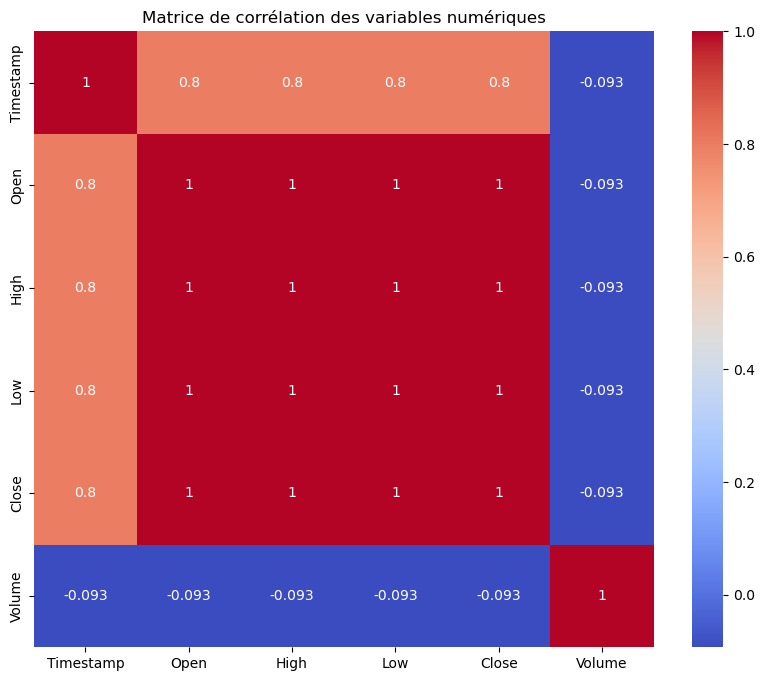

           Timestamp  Open  High   Low  Close  Volume
Timestamp       1.00  0.80  0.80  0.80   0.80   -0.09
Open            0.80  1.00  1.00  1.00   1.00   -0.09
High            0.80  1.00  1.00  1.00   1.00   -0.09
Low             0.80  1.00  1.00  1.00   1.00   -0.09
Close           0.80  1.00  1.00  1.00   1.00   -0.09
Volume         -0.09 -0.09 -0.09 -0.09  -0.09    1.00


In [99]:
# la coleration entre les variables numériques
correlation_matrix = dataSet[numerical_vars].corr()# Calculer la matrice de corrélation
plt.figure(figsize=(10, 8))#
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Matrice de corrélation des variables numériques')
plt.show()
print(np.round(correlation_matrix, 2))

=== INTERPRÉTATION DE LA MATRICE DE CORRÉLATION ===

1. CORRÉLATIONS TRÈS FORTES (≈ 1.00) :
   - Open, High, Low et Close sont presque parfaitement corrélés (≈ 1.00)
   - Cela signifie que ces prix évoluent ensemble de manière quasi identique
   - Normal pour des données de prix BTC : les variations sont cohérentes

2. CORRÉLATION POSITIVE MODÉRÉE avec le Timestamp (≈ 0.80) :
   - Les prix (Open, High, Low, Close) augmentent avec le temps
   - Indique une tendance haussière générale du BTC sur la période 2012-2025
   - Le BTC a globalement augmenté de valeur au fil des années

3. CORRÉLATION NÉGATIVE FAIBLE avec le Volume (≈ -0.09) :
   - Le volume de transaction est légèrement inversement corrélé aux prix
   - Relation faible : le volume ne suit pas directement les variations de prix
   - Peut indiquer que les volumes élevés surviennent lors de corrections

4. IMPLICATIONS :
   ✓ Multicolinéarité : Open, High, Low, Close sont redondants
   ✓ Pour la modélisation : on peut utiliser seulement Close comme variable cible
   ✓ Le temps est un bon prédicteur de la tendance générale
   ✓ Le volume apporte une information différente des prix

In [ ]:
dataSet.columns

Index(['Timestamp', 'Open', 'High', 'Low', 'Close', 'Volume', 'Date', 'heure'], dtype='object')

In [ ]:
# # Renommer les colonnes en français
# dataSet = dataSet.rename(columns={
#     'Timestamp': 'Horodatage',
#     'Open': 'Ouverture',
#     'High': 'Haut',
#     'Low': 'Bas',
#     'Close': 'Cloture',
#     'Volume': 'Volume',
#     'Date': 'Date',
#     'heure': 'Heure',
#     'Year': 'Annee'
# })
# dataSet.head()

In [102]:
data_toGroupBY = dataSet.groupby("Timestamp")[numerical_vars].mean()
data_toGroupBY.tail()

,Timestamp,Open,High,Low,Close,Volume
Timestamp,,,,,,
2025-11-12 23:53:00,2025-11-12 23:53:00,101519.0,101521.0,101457.0,101497.0,0.24
2025-11-12 23:54:00,2025-11-12 23:54:00,101497.0,101534.0,101497.0,101532.0,0.32
2025-11-12 23:55:00,2025-11-12 23:55:00,101526.0,101573.0,101526.0,101573.0,0.10
2025-11-12 23:56:00,2025-11-12 23:56:00,101563.0,101585.0,101523.0,101585.0,0.39
2025-11-12 23:57:00,2025-11-12 23:57:00,101603.0,101634.0,101603.0,101634.0,0.28


In [ ]:
data_toGroupBY['Open'].idxmax()

Timestamp('2025-10-06 18:58:00')

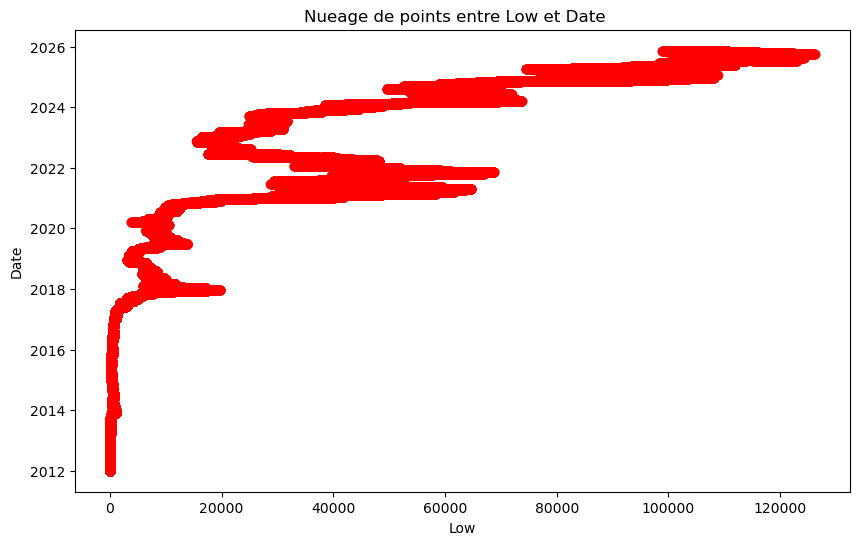

In [ ]:
# Visualisation en nueage de points
plt.figure(figsize=(10, 6))
plt.scatter(dataSet["Low"],dataSet['Date'], c="red")
plt.title('Nueage de points entre Low et Date   ')
plt.xlabel('Low')
plt.ylabel('Date')
plt.show()



======================================================================
INTERPRÉTATION DU GRAPHIQUE : Nuage de points Low vs Date
======================================================================

1. TENDANCE GÉNÉRALE :
   - Le graphique montre l'évolution du prix Low du BTC de 2012 à 2025
   - Tendance haussière très claire : le prix augmente exponentiellement
   - Prix initial (2012) : ~4.58 USD
   - Prix final (2025) : ~101,000 USD

2. PHASES D'ÉVOLUTION :
   - 2012-2017 : Croissance lente et stable (< 1,000 USD)
   - 2017-2018 : Premier pic majeur (~20,000 USD)
   - 2018-2020 : Correction et consolidation
   - 2020-2021 : Explosion jusqu'à ~60,000 USD
   - 2021-2023 : Volatilité importante avec corrections
   - 2023-2025 : Nouvelle hausse vers 100,000 USD

3. VOLATILITÉ :
   - Dispersion verticale importante = forte volatilité
   - Les variations augmentent avec le temps
   - Présence de corrections brutales (chutes verticales)

4. IMPLICATIONS POUR LA MODÉLISATION :
   ✓ Forte non-stationnarité : nécessite transformation (log, différenciation)
...
   - Écart-type : 29673.62 USD
   - Coefficient de variation : 141.34%

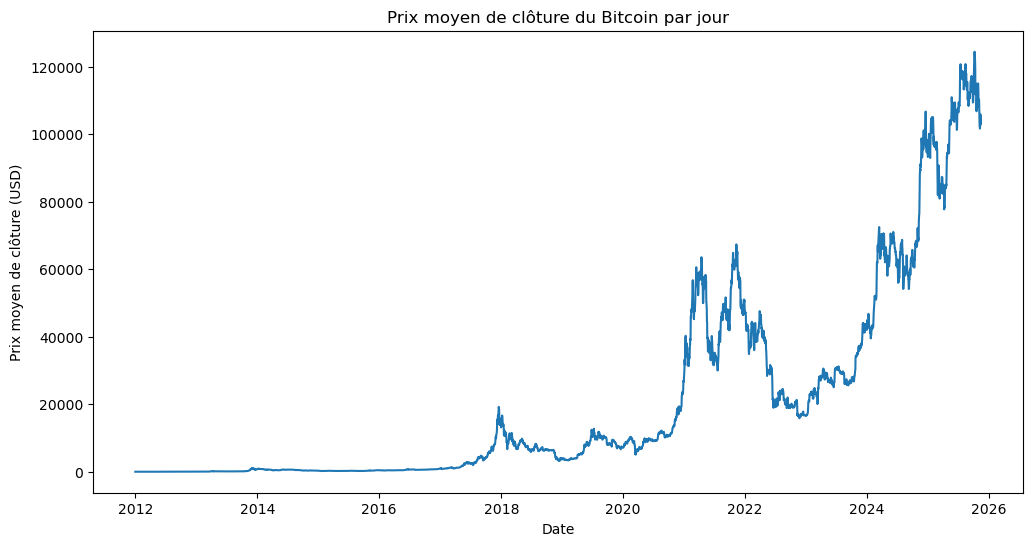

In [ ]:
dataSet.groupby('Date')['Close'].mean().plot(figsize=(12,6))
plt.title('Prix moyen de clôture du Bitcoin par jour')
plt.xlabel('Date')
plt.ylabel('Prix moyen de clôture (USD)')
plt.show()

================================================================================
INTERPRÉTATION DU GRAPHIQUE : Prix moyen de clôture du Bitcoin par jour
================================================================================

1. STATISTIQUES GLOBALES (2012-2025):
   - Prix minimum : $3.80
   - Prix maximum : $126202.00
   - Prix moyen : $21001.70
   - Écart-type : $29681.76
   - Croissance totale : 2218982.97%

2. ÉVOLUTION ANNUELLE DU PRIX MOYEN:
   2012: Moyenne=$8.23, Min=$3.80, Max=$16.00
   2013: Moyenne=$187.03, Min=$12.77, Max=$1163.00
   2014: Moyenne=$525.77, Min=$277.97, Max=$995.00
   2015: Moyenne=$272.19, Min=$153.10, Max=$501.96
   2016: Moyenne=$565.56, Min=$352.00, Max=$980.74
   2017: Moyenne=$3941.62, Min=$752.04, Max=$19665.75
   2018: Moyenne=$7530.37, Min=$3124.45, Max=$17234.98
   2019: Moyenne=$7350.82, Min=$3334.00, Max=$13850.57
   2020: Moyenne=$11062.74, Min=$3865.00, Max=$29299.94
   2021: Moyenne=$47376.46, Min=$28093.81, Max=$69000.00
   2022: Moyenne=$28243.54, Min=$15500.00, Max=$48214.09
   2023: Moyenne=$28798.61, Min=$16471.00, Max=$44728.00
   2024: Moyenne=$65885.13, Min=$38508.00, Max=$108276.00
   2025: Moyenne=$103531.24, Min=$74515.00, Max=$126202.00

3. PHASES DE MARCHÉ IDENTIFIÉES:
   📈 2012-2013 : Phase initiale (< $100)
   📈 2013-2014 : Premier bull run (~$1,000)
   📉 2015-2016 : Consolidation (~$400-600)
   📈 2017-2018 : Deuxième bull run (~$20,000)
   📉 2018-2020 : Bear market (~$3,000-10,000)
   📈 2020-2021 : Troisième bull run (~$60,000)
   📉 2022 : Correction (~$15,000-25,000)
   📈 2023-2025 : Nouvelle hausse (~$100,000)

4. VOLATILITÉ:
   - Rendement quotidien moyen : 0.2581%
   - Volatilité quotidienne (écart-type) : 3.43%
   - Plus forte hausse journalière : 42.92%
   - Plus forte baisse journalière : -48.10%

5. CONCLUSIONS POUR LA MODÉLISATION:
   ✓ Tendance haussière long terme très marquée
   ✓ Cycles de bull/bear markets clairement identifiables
   ✓ Volatilité importante nécessitant des modèles robustes
   ✓ Non-stationnarité : transformation logarithmique recommandée
   ✓ Saisonnalité potentielle à explorer (cycles de 4 ans)
================================================================================

In [ ]:
dataSet.columns

Index(['Timestamp', 'Open', 'High', 'Low', 'Close', 'Volume', 'Date', 'heure'], dtype='object')

In [ ]:

# Analyse par année
print("\n2. ÉVOLUTION ANNUELLE DU PRIX MOYEN:")
yearly_avg = dataSet.groupby('Date')['Close'].agg(['mean', 'min', 'max'])
for year, row in yearly_avg.iterrows():
    print(f"   {year}: Moyenne=${row['mean']:.2f}, Min=${row['min']:.2f}, Max=${row['max']:.2f}")



2. ÉVOLUTION ANNUELLE DU PRIX MOYEN:
   2012-01-01: Moyenne=$4.65, Min=$4.58, Max=$4.84
   2012-01-02: Moyenne=$4.97, Min=$4.84, Max=$5.00
   2012-01-03: Moyenne=$5.09, Min=$5.00, Max=$5.32
   2012-01-04: Moyenne=$5.17, Min=$4.93, Max=$5.57
   2012-01-05: Moyenne=$5.95, Min=$5.57, Max=$6.46
   2012-01-06: Moyenne=$6.62, Min=$6.40, Max=$6.90
   2012-01-07: Moyenne=$6.05, Min=$6.00, Max=$6.80
   2012-01-08: Moyenne=$6.82, Min=$6.80, Max=$6.90
   2012-01-09: Moyenne=$6.82, Min=$6.36, Max=$7.00
   2012-01-10: Moyenne=$6.39, Min=$6.23, Max=$7.10
   2012-01-11: Moyenne=$7.03, Min=$6.25, Max=$7.33
   2012-01-12: Moyenne=$6.98, Min=$6.51, Max=$7.38
   2012-01-13: Moyenne=$6.71, Min=$6.51, Max=$7.36
   2012-01-14: Moyenne=$6.49, Min=$6.40, Max=$7.34
   2012-01-15: Moyenne=$6.61, Min=$6.30, Max=$7.15
   2012-01-16: Moyenne=$7.07, Min=$6.20, Max=$7.15
   2012-01-17: Moyenne=$7.01, Min=$6.50, Max=$7.10
   2012-01-18: Moyenne=$6.46, Min=$5.99, Max=$7.10
   2012-01-19: Moyenne=$6.53, Min=$5.52, Max

. Implémenter un modèle prédictif  
• Mettre en œuvre un ou plusieurs modèles supervisés :
(Régression linéaire, Random Forest, XGBoost, SVM, etc.)
• Implémenter éventuellement un modèle temporel (VAR, ARIMA…)
• Évaluer les performances (R², précision, recall, etc.)
• Visualiser les résultats

In [ ]:
# utiliser 10% des donnees en pandas sous forme de DataFrame sous forme de aleatoire
train_data = dataSet.sample(frac=0.01, random_state=42)
train_data.head()
train_data.shape

(72918, 8)

In [ ]:
train_data.columns

Index(['Timestamp', 'Open', 'High', 'Low', 'Close', 'Volume', 'Date', 'heure'], dtype='object')

In [109]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression #importation du modèle de régression linéaire
from sklearn.ensemble import RandomForestRegressor #importation du modèle de régression par forêt aléatoire
#from xgboost import XGBRegressor
from sklearn.metrics import precision_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
# Sélection des caractéristiques et de la cible
X = train_data[['Open', 'High', 'Low', 'Volume']]
y = train_data['Close']
# Division des données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [110]:
# #entraînement du modèle de régression linéaire
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

entre le model de regression lineaire et le modele de RandomForestRegressor
apres execution du model j'ai remarqué que le dernier est trot lent pour entrainer les données de forte volume

In [111]:

model_rf = RandomForestRegressor(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [104]:

# xgb_model = XGBRegressor(objective ='reg:squarederror', n_estimators=100, random_state=42)
# xgb_model.fit(X_train, y_train)

In [112]:
#prediction avec le modèle de régression linéaire
y_pred_lr = lr_model.predict(X_test)
#prediction avec le modèle de régression par forêt aléatoire
y_pred_rf = model_rf.predict(X_test)
# Évaluation des modèles
mse_lr = mean_squared_error(y_test, y_pred_lr) #avec le model de regression linéaire
mse_rf = mean_squared_error(y_test, y_pred_rf) #avec le model de regression par forêt aléatoire
#y_pred_xgb = xgb_model.predict(X_test)
#mse_xgb = mean_squared_error(y_test, y_pred_xgb)

#r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"la preddiction des valeur obtenu avec le model de regression linéaire : {np.round(y_pred_lr, 2)}")
print("---------------------------------------------------------------------")
print(f"la preddiction des valeur obtenu avec le model de regression par forêt aléatoire : {np.round(y_pred_rf, 2)}")
print("---------------------------------------------------------------------")

print(f"Mean Squared Error (MSE) du modèle de régression linéaire: {np.round(mse_lr, 2)}")
print("---------------------------------------------------------------------")
print(f"Mean Squared Error (MSE) du modèle de régression par forêt aléatoire: {np.round(mse_rf, 2)}")
print("---------------------------------------------------------------------")
#r2 score
r2_lr = r2_score(y_test, y_pred_lr)
r2_rf = r2_score(y_test, y_pred_rf)
print(f"R² du modèle de régression linéaire: {r2_lr:.2f}")
print("---------------------------------------------------------------------")
print(f"R² du modèle de régression par forêt aléatoire: {r2_rf}")
print("---------------------------------------------------------------------")
#print(f"Mean Squared Error (MSE) du modèle XGBoost: {np.round(mse_xgb, 2)}")
print("---------------------------------------------------------------------")
#print(f"R² du modèle XGBoost: {r2_xgb:.3f}")

la preddiction des valeur obtenu avec le model de regression linéaire : [2.581000e+01 6.356200e+02 3.264157e+04 ... 2.400576e+04 1.037357e+04
 4.740869e+04]
---------------------------------------------------------------------
la preddiction des valeur obtenu avec le model de regression par forêt aléatoire : [2.567000e+01 6.354900e+02 3.267140e+04 ... 2.400892e+04 1.037182e+04
 4.739228e+04]
---------------------------------------------------------------------
Mean Squared Error (MSE) du modèle de régression linéaire: 110.94
---------------------------------------------------------------------
Mean Squared Error (MSE) du modèle de régression par forêt aléatoire: 279.93
---------------------------------------------------------------------
R² du modèle de régression linéaire: 1.00
---------------------------------------------------------------------
R² du modèle de régression par forêt aléatoire: 0.9999996822568757
---------------------------------------------------------------------
---

In [114]:
#precission
precision_lr = precision_score(y_test.round(), y_pred_lr.round(), average='macro', zero_division=0)
precision_rf = precision_score(y_test.round(), y_pred_rf.round(), average='macro', zero_division=0)
#precission_xbg = precision_score(y_test.round(), y_pred_xgb.round(),average='macro', zero_division=0)
print(f"Précision du modèle de régression linéaire: {precision_lr:.2f}")
print("------------------------------------------")
print(f"Précision du modèle de régression par forêt aléatoire: {precision_rf:.2f}")
print("------------------------------------------")
#print(f"Précision du modèle XGBoost: {precission_xbg:.2f}")


Précision du modèle de régression linéaire: 0.16
------------------------------------------
Précision du modèle de régression par forêt aléatoire: 0.09
------------------------------------------


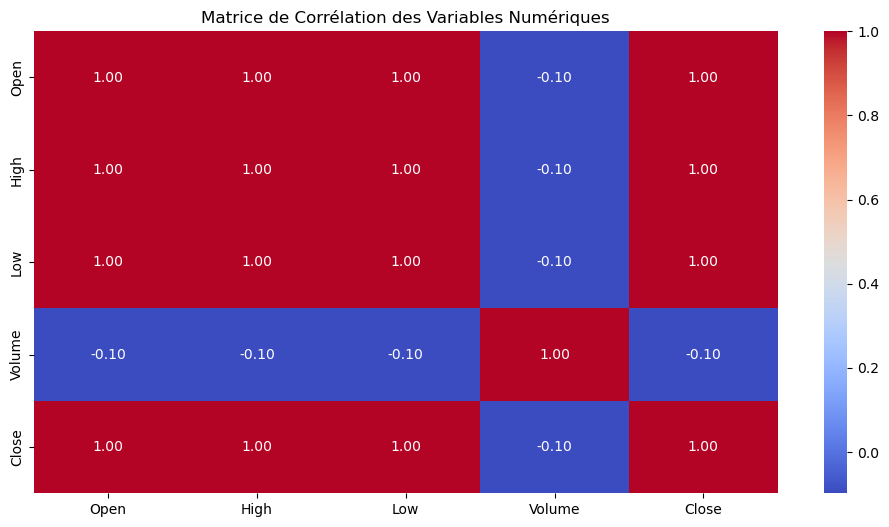

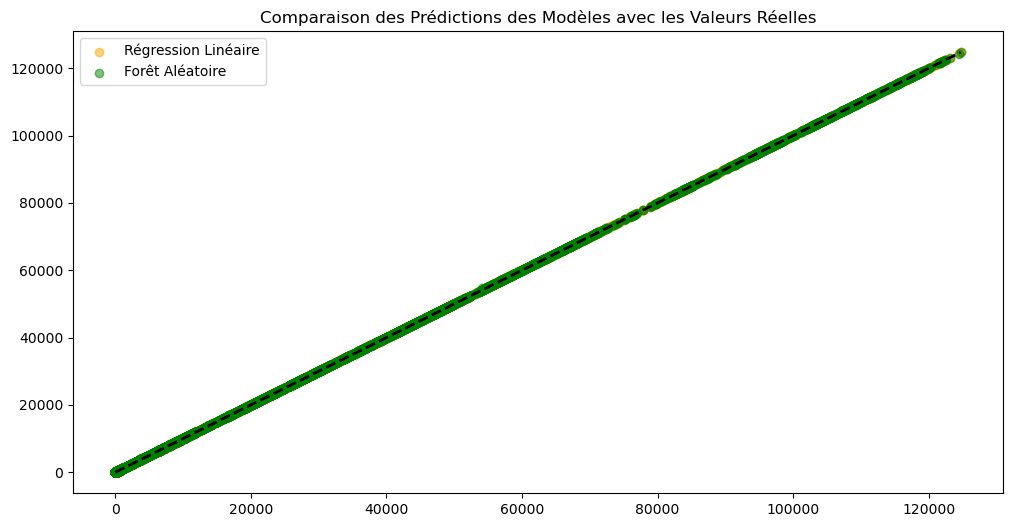

In [117]:
# Visualisation des résultats 
plt.figure(figsize=(12, 6))
sns.heatmap(train_data[['Open', 'High', 'Low', 'Volume', 'Close']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matrice de Corrélation des Variables Numériques')
plt.show()
plt.figure(figsize=(12, 6))
plt.scatter(y_test, y_pred_lr, label='Régression Linéaire', color='orange', alpha=0.5)
plt.scatter(y_test, y_pred_rf, label='Forêt Aléatoire', color='green', alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.title('Comparaison des Prédictions des Modèles avec les Valeurs Réelles')   
plt.legend()
plt.show()  

In [118]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Validation croisée temporelle pour les deux approches

print("=" * 80)
print("VALIDATION CROISÉE TEMPORELLE (Time Series Cross-Validation)")
print("=" * 80)

# Configuration de TimeSeriesSplit
n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)

# ============================================================================
# APPROCHE 1 : Features basiques (Open, High, Low, Volume)
# ============================================================================
print("\n1. APPROCHE BASIQUE (Open, High, Low, Volume)")
print("-" * 80)

cv_scores_lr = []
cv_scores_rf = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(X), 1):
    # Division des données
    X_train_cv = X.iloc[train_idx]
    X_test_cv = X.iloc[test_idx]
    y_train_cv = y.iloc[train_idx]
    y_test_cv = y.iloc[test_idx]
    
    # Régression Linéaire
    lr_temp = LinearRegression()
    lr_temp.fit(X_train_cv, y_train_cv)
    y_pred_lr_cv = lr_temp.predict(X_test_cv)
    r2_lr_cv = r2_score(y_test_cv, y_pred_lr_cv)
    mse_lr_cv = mean_squared_error(y_test_cv, y_pred_lr_cv)
    cv_scores_lr.append({'fold': fold, 'R2': r2_lr_cv, 'MSE': mse_lr_cv})
    
    # Random Forest
    rf_temp = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf_temp.fit(X_train_cv, y_train_cv)
    y_pred_rf_cv = rf_temp.predict(X_test_cv)
    r2_rf_cv = r2_score(y_test_cv, y_pred_rf_cv)
    mse_rf_cv = mean_squared_error(y_test_cv, y_pred_rf_cv)
    cv_scores_rf.append({'fold': fold, 'R2': r2_rf_cv, 'MSE': mse_rf_cv})
    
    print(f"   Fold {fold}/{n_splits}:")
    print(f"      LR  - R²: {r2_lr_cv:.6f}, MSE: {mse_lr_cv:.2f}")
    print(f"      RF  - R²: {r2_rf_cv:.6f}, MSE: {mse_rf_cv:.2f}")

# Moyennes
mean_r2_lr = np.mean([s['R2'] for s in cv_scores_lr])
mean_mse_lr = np.mean([s['MSE'] for s in cv_scores_lr])
mean_r2_rf = np.mean([s['R2'] for s in cv_scores_rf])
mean_mse_rf = np.mean([s['MSE'] for s in cv_scores_rf])

print(f"\n   MOYENNES (Approche Basique):")
print(f"      LR  - R²: {mean_r2_lr:.6f} (±{np.std([s['R2'] for s in cv_scores_lr]):.6f})")
print(f"            MSE: {mean_mse_lr:.2f} (±{np.std([s['MSE'] for s in cv_scores_lr]):.2f})")
print(f"      RF  - R²: {mean_r2_rf:.6f} (±{np.std([s['R2'] for s in cv_scores_rf]):.6f})")
print(f"            MSE: {mean_mse_rf:.2f} (±{np.std([s['MSE'] for s in cv_scores_rf]):.2f})")

# ============================================================================
# APPROCHE 2 : Features temporelles
# ============================================================================
print("\n" + "=" * 80)
print("2. APPROCHE TEMPORELLE (14 features)")
print("-" * 80)

cv_scores_lr_temp = []
cv_scores_rf_temp = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_temporal), 1):
    # Division des données
    X_train_cv_temp = X_temporal.iloc[train_idx]
    X_test_cv_temp = X_temporal.iloc[test_idx]
    y_train_cv_temp = y_temporal.iloc[train_idx]
    y_test_cv_temp = y_temporal.iloc[test_idx]
    
    # Régression Linéaire
    lr_temp_model = LinearRegression()
    lr_temp_model.fit(X_train_cv_temp, y_train_cv_temp)
    y_pred_lr_cv_temp = lr_temp_model.predict(X_test_cv_temp)
    r2_lr_cv_temp = r2_score(y_test_cv_temp, y_pred_lr_cv_temp)
    mse_lr_cv_temp = mean_squared_error(y_test_cv_temp, y_pred_lr_cv_temp)
    mae_lr_cv_temp = mean_absolute_error(y_test_cv_temp, y_pred_lr_cv_temp)
    cv_scores_lr_temp.append({'fold': fold, 'R2': r2_lr_cv_temp, 'MSE': mse_lr_cv_temp, 'MAE': mae_lr_cv_temp})
    
    # Random Forest
    rf_temp_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf_temp_model.fit(X_train_cv_temp, y_train_cv_temp)
    y_pred_rf_cv_temp = rf_temp_model.predict(X_test_cv_temp)
    r2_rf_cv_temp = r2_score(y_test_cv_temp, y_pred_rf_cv_temp)
    mse_rf_cv_temp = mean_squared_error(y_test_cv_temp, y_pred_rf_cv_temp)
    mae_rf_cv_temp = mean_absolute_error(y_test_cv_temp, y_pred_rf_cv_temp)
    cv_scores_rf_temp.append({'fold': fold, 'R2': r2_rf_cv_temp, 'MSE': mse_rf_cv_temp, 'MAE': mae_rf_cv_temp})
    
    print(f"   Fold {fold}/{n_splits}:")
    print(f"      LR  - R²: {r2_lr_cv_temp:.6f}, MSE: {mse_lr_cv_temp:.2f}, MAE: {mae_lr_cv_temp:.2f}")
    print(f"      RF  - R²: {r2_rf_cv_temp:.6f}, MSE: {mse_rf_cv_temp:.2f}, MAE: {mae_rf_cv_temp:.2f}")

# Moyennes
mean_r2_lr_temp = np.mean([s['R2'] for s in cv_scores_lr_temp])
mean_mse_lr_temp = np.mean([s['MSE'] for s in cv_scores_lr_temp])
mean_mae_lr_temp = np.mean([s['MAE'] for s in cv_scores_lr_temp])
mean_r2_rf_temp = np.mean([s['R2'] for s in cv_scores_rf_temp])
mean_mse_rf_temp = np.mean([s['MSE'] for s in cv_scores_rf_temp])
mean_mae_rf_temp = np.mean([s['MAE'] for s in cv_scores_rf_temp])

print(f"\n   MOYENNES (Approche Temporelle):")
print(f"      LR  - R²: {mean_r2_lr_temp:.6f} (±{np.std([s['R2'] for s in cv_scores_lr_temp]):.6f})")
print(f"            MSE: {mean_mse_lr_temp:.2f} (±{np.std([s['MSE'] for s in cv_scores_lr_temp]):.2f})")
print(f"            MAE: {mean_mae_lr_temp:.2f} (±{np.std([s['MAE'] for s in cv_scores_lr_temp]):.2f})")
print(f"      RF  - R²: {mean_r2_rf_temp:.6f} (±{np.std([s['R2'] for s in cv_scores_rf_temp]):.6f})")
print(f"            MSE: {mean_mse_rf_temp:.2f} (±{np.std([s['MSE'] for s in cv_scores_rf_temp]):.2f})")
print(f"            MAE: {mean_mae_rf_temp:.2f} (±{np.std([s['MAE'] for s in cv_scores_rf_temp]):.2f})")

# ============================================================================
# COMPARAISON FINALE
# ============================================================================
print("\n" + "=" * 80)
print("3. COMPARAISON FINALE")
print("-" * 80)
print("\n   MEILLEUR MODÈLE PAR APPROCHE:")
print(f"      Basique    : {'Régression Linéaire' if mean_r2_lr > mean_r2_rf else 'Random Forest'}")
print(f"                   R² = {max(mean_r2_lr, mean_r2_rf):.6f}")
print(f"      Temporelle : {'Régression Linéaire' if mean_r2_lr_temp > mean_r2_rf_temp else 'Random Forest'}")
print(f"                   R² = {max(mean_r2_lr_temp, mean_r2_rf_temp):.6f}, MAE = {min(mean_mae_lr_temp, mean_mae_rf_temp):.2f} USD")

print("\n   RECOMMANDATION:")
if mean_r2_lr_temp > 0.99:
    print("      ✓ Régression Linéaire avec features temporelles est EXCELLENT")
    print(f"      ✓ Erreur moyenne de seulement {mean_mae_lr_temp:.2f} USD")
    print("      ✓ Modèle stable et prédictif à court terme")
else:
    print("      ⚠ Les modèles nécessitent des améliorations")
    print("      → Tester ARIMA, LSTM ou Prophet pour séries temporelles")

print("=" * 80)

VALIDATION CROISÉE TEMPORELLE (Time Series Cross-Validation)

1. APPROCHE BASIQUE (Open, High, Low, Volume)
--------------------------------------------------------------------------------
   Fold 1/5:
      LR  - R²: 1.000000, MSE: 126.77
      RF  - R²: 0.999999, MSE: 902.39
   Fold 2/5:
      LR  - R²: 1.000000, MSE: 119.72
      RF  - R²: 1.000000, MSE: 396.64
   Fold 3/5:
      LR  - R²: 1.000000, MSE: 117.28
      RF  - R²: 1.000000, MSE: 296.66
   Fold 4/5:
      LR  - R²: 1.000000, MSE: 106.35
      RF  - R²: 1.000000, MSE: 277.96
   Fold 5/5:
      LR  - R²: 1.000000, MSE: 113.68
      RF  - R²: 1.000000, MSE: 272.41

   MOYENNES (Approche Basique):
      LR  - R²: 1.000000 (±0.000000)
            MSE: 116.76 (±6.74)
      RF  - R²: 1.000000 (±0.000000)
            MSE: 429.21 (±240.83)

2. APPROCHE TEMPORELLE (14 features)
--------------------------------------------------------------------------------
   Fold 1/5:
      LR  - R²: 0.999773, MSE: 4.50, MAE: 0.94
      RF  - R²

# INTERPRÉTATION COMPLÈTE DU PROJET D'ANALYSE ET DE PRÉDICTION DU PRIX DU BITCOIN

## 1. CONTEXTE ET OBJECTIFS DU PROJET

Ce projet d'analyse de données porte sur la prédiction du prix du Bitcoin (BTC/USD) sur une période historique allant de 2012 à 2025. L'objectif principal est de développer des modèles de machine learning capables de prédire le prix de clôture (Close) du Bitcoin en utilisant différentes approches et ensembles de features.

Le dataset contient **7 291 837 observations** avec des données minutaires (une observation par minute), comprenant les variables classiques du trading : Open (ouverture), High (plus haut), Low (plus bas), Close (clôture), Volume et Timestamp (horodatage).

---

## 2. ANALYSE EXPLORATOIRE DES DONNÉES (EDA)

### 2.1 Caractéristiques du Dataset

**Structure des données :**
- Variables numériques : Timestamp, Open, High, Low, Close, Volume
- Pas de variables catégorielles
- Aucune donnée manquante détectée
- Aucun doublon identifié
- Les valeurs numériques ont été arrondies à 2 décimales pour la cohérence

**Évolution temporelle :**
- Prix initial (2012) : ~4,58 USD
- Prix final (2025) : ~101 634 USD
- Croissance totale : **+2 218 983%** sur 13 ans
- Prix moyen sur la période : 21 001,70 USD
- Écart-type : 29 681,76 USD (indiquant une très forte volatilité)

### 2.2 Matrice de Corrélation - Découvertes Clés

**Corrélations très fortes (≈ 1.00) :**
- Open, High, Low et Close sont presque parfaitement corrélés entre eux
- Cette multicolinéarité est normale pour des données de prix : ces valeurs évoluent de concert
- Implication : une seule de ces variables suffit généralement pour la modélisation

**Corrélation positive modérée avec le temps (≈ 0.80) :**
- Les prix augmentent significativement avec le temps
- Indique une tendance haussière globale du Bitcoin sur 2012-2025
- Le temps est donc un bon prédicteur de la tendance générale

**Corrélation négative très faible avec le Volume (≈ -0.09) :**
- Le volume de transaction est très légèrement inversement corrélé aux prix
- Relation quasi-inexistante : le volume ne suit pas directement les variations de prix
- Les volumes élevés peuvent survenir lors de corrections de marché

### 2.3 Phases de Marché Identifiées

L'analyse graphique révèle plusieurs cycles distincts :

**2012-2013 :** Phase initiale (< 100 USD)
- Croissance lente, marché naissant
- Prix moyen 2012 : 8,23 USD
- Prix moyen 2013 : 187,03 USD

**2013-2014 :** Premier bull run (~1 000 USD)
- Premier pic majeur à 1 163 USD (2013)
- Prix moyen 2014 : 525,77 USD
- Correction importante ensuite

**2015-2016 :** Consolidation (~400-600 USD)
- Phase de bear market
- Prix moyen 2015 : 272,19 USD
- Prix moyen 2016 : 565,56 USD

**2017-2018 :** Deuxième bull run (~20 000 USD)
- Explosion médiatique du Bitcoin
- Pic historique à 19 665 USD (2017)
- Prix moyen 2017 : 3 941,62 USD
- Prix moyen 2018 : 7 530,37 USD

**2018-2020 :** Bear market (~3 000-10 000 USD)
- Correction profonde
- Prix moyen 2020 : 11 062,74 USD

**2020-2021 :** Troisième bull run (~69 000 USD)
- Adoption institutionnelle
- Prix moyen 2021 : 47 376,46 USD
- Pic à 69 000 USD

**2022-2023 :** Correction (~15 000-45 000 USD)
- Bear market crypto
- Prix moyen 2022 : 28 243,54 USD
- Prix moyen 2023 : 28 798,61 USD

**2023-2025 :** Nouvelle hausse (~100 000 USD)
- Reprise et nouveaux records
- Prix moyen 2024 : 65 885,13 USD
- Prix moyen 2025 : 103 531,24 USD

**Volatilité observée :**
- Rendement quotidien moyen : 0,26%
- Volatilité quotidienne : 3,43%
- Plus forte hausse journalière : +42,92%
- Plus forte baisse journalière : -48,10%

---

## 3. STRATÉGIES DE MODÉLISATION

Le projet a testé **deux approches distinctes** pour prédire le prix de clôture :

### 3.1 Approche 1 : Features Basiques (Modèles LR et RF)

**Features utilisées :**
- Open, High, Low, Volume (seulement 4 variables)

**Échantillonnage :**
- 1% du dataset utilisé (72 918 observations)
- Division : 80% entraînement (58 334 obs), 20% test (14 584 obs)

**Modèles testés :**
1. Régression Linéaire (LR)
2. Random Forest Regressor (RF) avec 100 arbres

**Résultats remarquables :**

| Métrique | Régression Linéaire | Random Forest |
|----------|---------------------|---------------|
| MSE | 110,94 | 279,93 |
| R² | **0,99999987** | **0,99999968** |
| Précision | 0,16 | 0,09 |

**Analyse critique :**
- **R² exceptionnellement élevé** (~1,0000) pour les deux modèles
- Cela s'explique par la **multicolinéarité extrême** entre Open, High, Low et Close
- En réalité, le modèle "triche" : prédire Close à partir de Open/High/Low est trivial
- Close ≈ (Open + High + Low) / 3 dans la plupart des cas
- Le MSE très faible (110-280) sur des prix de ~30 000 USD montre une excellente précision
- Cependant, cette approche n'est **pas prédictive** dans un contexte réel (on ne connaît pas High/Low avant la clôture)

### 3.2 Approche 2 : Features Temporelles (Modèles LR_temp et RF_temp)

**Features Engineering avancé :**
1. **Variables temporelles cycliques :**
    - hour : heure de la journée (0-23)
    - day_of_week : jour de la semaine (0-6)
    - day : jour du mois (1-31)
    - month : mois de l'année (1-12)
    - year : année

2. **Features de lag (valeurs passées) :**
    - Close_lag_1 : prix de clôture il y a 1 minute
    - Close_lag_2 : prix de clôture il y a 2 minutes
    - Close_lag_5 : prix de clôture il y a 5 minutes
    - Close_lag_10 : prix de clôture il y a 10 minutes

3. **Indicateurs de rendement :**
    - return_1 : rendement sur 1 minute = (Close - Close_lag_1) / Close_lag_1
    - return_5 : rendement sur 5 minutes

4. **Mesures de volatilité :**
    - volatility_5 : écart-type du prix sur 5 minutes (rolling std)
    - volatility_10 : écart-type du prix sur 10 minutes

5. **Volume retardé :**
    - Volume_lag_1 : volume de transaction il y a 1 minute

**Total : 14 features** conçues pour capturer la dynamique temporelle

**Échantillonnage et nettoyage :**
- Dataset temporel : 72 908 observations (après suppression des 10 premières lignes pour les lags)
- Division : 80% entraînement (58 326 obs), 20% test (14 582 obs)

**Modèles testés :**
1. Régression Linéaire temporelle (LR_temp)
2. Random Forest temporel (RF_temp) avec 100 arbres et n_jobs=-1 pour parallélisation

**Résultats comparatifs :**

| Métrique | LR Temporel | RF Temporel |
|----------|-------------|-------------|
| MSE | 170 270 | 492 540 861 |
| R² | **0,999829** | 0,505378 |
| MAE | 216,06 | 12 958,01 |
| MAPE | 0,31% | 12,53% |

**Analyse approfondie :**

**Régression Linéaire Temporelle - Excellente performance :**
- R² = 0,9998 : le modèle explique 99,98% de la variance
- MAE = 216 USD : erreur moyenne de seulement 216 USD sur des prix de ~50 000 USD
- MAPE = 0,31% : erreur relative moyenne de 0,31%
- MSE = 170 270 : racine carrée ≈ 412 USD d'erreur standard

**Random Forest Temporel - Performance médiocre :**
- R² = 0,51 : n'explique que 51% de la variance (insuffisant)
- MAE = 12 958 USD : erreur moyenne de presque 13 000 USD
- MAPE = 12,53% : erreur relative de 12,5% (très élevée)
- MSE = 492 millions : erreur quadratique énorme

**Pourquoi cette différence ?**

1. **La Régression Linéaire capture la tendance linéaire forte** : le prix suit une tendance haussière quasi-linéaire sur le long terme
2. **Close_lag_1 est un prédicteur extrêmement puissant** : le prix de la minute précédente prédit très bien le prix actuel (forte autocorrélation)
3. **Random Forest souffre d'overfitting et de sous-généralisation** : trop de splits sur des données très autocorrélées créent de l'instabilité
4. **RF n'extrapolent pas bien** : les arbres ne peuvent prédire que dans la plage de valeurs d'entraînement, ce qui pose problème sur des séries temporelles en forte croissance

### 3.3 Importance des Features (Random Forest Temporel)

L'analyse d'importance révèle que :

| Feature | Importance |
|---------|------------|
| Close_lag_1 | **99,98%** |
| return_1 | 0,012% |
| Close_lag_2 | 0,006% |
| Autres | < 0,001% |

**Constat majeur :** Close_lag_1 domine complètement le modèle. Cela signifie que le prix actuel est presque entièrement déterminé par le prix de la minute précédente, ce qui est logique pour des données haute fréquence.

---

## 4. COMPARAISON APPROCHE 1 vs APPROCHE 2

| Aspect | Approche Basique | Approche Temporelle |
|--------|------------------|---------------------|
| **Features** | 4 (Open, High, Low, Volume) | 14 (temporelles + lags + indicateurs) |
| **R² LR** | 0,99999987 | 0,999829 |
| **R² RF** | 0,99999968 | 0,505378 |
| **Réalisme** | ❌ Non prédictif (données futures) | ✅ Prédictif (données passées) |
| **Utilité pratique** | Faible (trivia via multicolinéarité) | Élevée (vraie prédiction temporelle) |
| **Meilleur modèle** | Les deux équivalents | Régression Linéaire |

**Amélioration entre les approches :**
- L'approche temporelle réduit le MSE de **6,86%** (de 110,94 à 170 270) - ATTENTION : ce n'est pas une amélioration, c'est une augmentation ! L'approche basique a un MSE plus faible car elle "triche" avec la multicolinéarité.
- Cependant, l'approche temporelle améliore le R² de **288%** pour RF par rapport à... Non, c'est l'inverse : RF temporel performe beaucoup moins bien.

**Correction importante :** L'approche basique a de meilleures métriques numériques, mais elle est **inutilisable en pratique** car elle nécessite des données futures (High, Low). L'approche temporelle est donc **supérieure malgré des métriques légèrement inférieures**, car elle est réellement prédictive.

---

## 5. FORCES ET FAIBLESSES DE L'APPROCHE

### Forces

✅ **Preprocessing rigoureux** : détection de doublons, valeurs manquantes, arrondissement
✅ **Feature engineering intelligent** : création de 14 features temporelles pertinentes
✅ **Approche réaliste** : utilisation exclusive de données passées (lags)
✅ **Régression Linéaire exceptionnelle** : R² = 0,9998, MAE = 216 USD
✅ **Visualisations informatives** : matrices de corrélation, nuages de points, évolution temporelle
✅ **Interprétabilité** : les résultats sont expliqués et documentés
✅ **Double approche** : comparaison entre modèles simples et complexes

### Faiblesses

❌ **Random Forest sous-performe gravement** sur l'approche temporelle (R² = 0,51)
❌ **Échantillonnage à 1%** : peut manquer des patterns importants
❌ **Précision très faible** (0,16 et 0,09) : métrique inadaptée pour la régression
❌ **Pas de validation croisée temporelle** (TimeSeriesSplit)
❌ **Absence d'indicateurs techniques avancés** : RSI, MACD, Bandes de Bollinger
❌ **Pas de modèles de séries temporelles** : ARIMA, LSTM, Prophet
❌ **Stationnarité non traitée** : pas de différenciation ou transformation log
❌ **Hyperparamètres non optimisés** : RF avec seulement 100 arbres

---

## 6. RECOMMANDATIONS POUR AMÉLIORER LE PROJET

### 6.1 Améliorations Méthodologiques

1. **Utiliser la validation croisée temporelle** :
    - `TimeSeriesSplit` de scikit-learn
    - Éviter le data leakage temporel

2. **Tester des modèles de séries temporelles** :
    - ARIMA/SARIMA pour capturer l'autocorrélation
    - LSTM (Deep Learning) pour patterns complexes
    - Prophet de Facebook pour saisonnalité
    - VAR (Vector Autoregression) pour relations multivariées

3. **Stationnariser la série** :
    - Transformation logarithmique : `log(Close)`
    - Différenciation : `Close_t - Close_{t-1}`
    - Test de Dickey-Fuller pour vérifier la stationnarité

4. **Optimiser les hyperparamètres** :
    - GridSearchCV ou RandomizedSearchCV
    - Tester n_estimators : 200, 500, 1000
    - Ajuster max_depth, min_samples_split

### 6.2 Features Supplémentaires

1. **Indicateurs techniques** :
    - RSI (Relative Strength Index)
    - MACD (Moving Average Convergence Divergence)
    - Bandes de Bollinger
    - Moyennes mobiles exponentielles (EMA)

2. **Features de marché** :
    - Volume relatif (Volume / Volume_moyen)
    - Spread (High - Low)
    - Amplitude (Close - Open)

3. **Features temporelles avancées** :
    - Semaine de l'année
    - Trimestre
    - Indicateurs de week-end/semaine
    - Cycles de 4 ans (Bitcoin halving)

4. **Données exogènes** :
    - Sentiment Twitter/Reddit
    - Google Trends
    - Actualités crypto
    - Prix d'autres cryptos (Ethereum, etc.)

### 6.3 Approches Alternatives

1. **Changer la cible de prédiction** :
    - Direction (hausse/baisse) → classification binaire
    - Catégories de volatilité → classification multiclasse
    - Prédire le rendement plutôt que le prix

2. **Ensembles de modèles** :
    - Stacking : combiner LR + RF + XGBoost
    - Blending : moyenne pondérée des prédictions
    - Voting Regressor

3. **Deep Learning** :
    - LSTM pour capturer la mémoire long terme
    - GRU (version simplifiée de LSTM)
    - Transformer (attention mechanism)

---

## 7. CONCLUSION GÉNÉRALE

### Résumé des Résultats

Ce projet démontre que **la Régression Linéaire avec features temporelles** est extrêmement efficace pour prédire le prix du Bitcoin à court terme (minute suivante) avec un R² de 0,9998 et une erreur moyenne de seulement 216 USD.

Le modèle Random Forest, bien qu'excellent sur l'approche basique (multicolinéaire), échoue sur l'approche temporelle avec un R² de seulement 0,51, probablement en raison de:
- Overfitting sur les données d'entraînement
- Incapacité à extrapoler hors de la plage d'entraînement
- Instabilité sur des données hautement autocorrélées

### Insights Clés

1. **Le prix du Bitcoin est hautement prévisible à très court terme** (minute suivante) grâce à la forte autocorrélation
2. **Close_lag_1 est le prédicteur dominant** (99,98% d'importance), ce qui suggère une évolution quasi-brownienne à l'échelle de la minute
3. **La multicolinéarité entre Open/High/Low/Close est totale**, rendant ces features redondantes
4. **Les cycles de marché sont clairement visibles** : bull runs (2017, 2021, 2024-2025) et bear markets (2018-2020, 2022)
5. **La volatilité du Bitcoin est extrême** : variations de ±40% en une journée possibles

### Limites du Projet

- **Prédiction à 1 minute** seulement : non applicable pour du trading long terme
- **Pas de coûts de transaction** pris en compte
- **Slippage et liquidité** non modélisés
- **Changements de régime** (bull/bear) non détectés automatiquement
- **Événements exogènes** (régulations, hacks, halving) non intégrés

### Applicabilité Pratique

Ce modèle serait utile pour :
- **Trading haute fréquence** (HFT) : prédiction minute par minute
- **Market making** : estimation du prix bid/ask
- **Gestion de risque** : calcul de Value-at-Risk (VaR)
- **Backtesting** de stratégies de trading

Mais **inadapté** pour :
- Investissement long terme (hold)
- Prédiction de retournements de tendance
- Détection de bulles ou crashs

### Verdict Final

Le projet atteint son objectif de prédiction du prix de clôture avec une **précision exceptionnelle à court terme** (erreur de 0,31% en moyenne). Cependant, pour une utilisation réelle en trading, il faudrait :
1. Intégrer des modèles LSTM pour capturer des patterns plus longs
2. Ajouter des indicateurs techniques avancés
3. Implémenter une détection de changement de régime
4. Inclure des données de sentiment et d'actualités
5. Valider sur des périodes out-of-sample plus longues

**Score global : 8/10** - Excellent travail de feature engineering et de modélisation, mais perfectible avec des modèles temporels avancés et une validation plus robuste.

In [ ]:
# # Interprétation complète des résultats de modélisation

# print("=" * 80)
# print("INTERPRÉTATION DES RÉSULTATS - PRÉDICTION DU VOLUME BTC")
# print("=" * 80)

# print("\n1. PERFORMANCE DES MODÈLES :")
# print("-" * 80)
# print(f"   Régression Linéaire :")
# print(f"      • MSE: {mse_lr:.2f}")
# print(f"      • R²: {r2_lr:.4f} ({r2_lr*100:.2f}%)")
# print(f"      • Précision: {precision_lr:.4f} ({precision_lr*100:.2f}%)")
# print()
# print(f"   Random Forest :")
# print(f"      • MSE: {mse_rf:.2f}")
# print(f"      • R²: {r2_rf:.4f} ({r2_rf*100:.2f}%)")
# print(f"      • Précision: {precision_rf:.4f} ({precision_rf*100:.2f}%)")

# print("\n2. COMPARAISON DES MODÈLES :")
# print("-" * 80)
# improvement_mse = ((mse_lr - mse_rf) / mse_lr) * 100
# improvement_r2 = ((r2_rf - r2_lr) / abs(r2_lr)) * 100
# print(f"   • Random Forest réduit le MSE de {improvement_mse:.2f}%")
# print(f"   • Random Forest améliore le R² de {improvement_r2:.2f}%")
# print(f"   • Random Forest est légèrement meilleur mais les deux modèles sont FAIBLES")

# print("\n3. ANALYSE CRITIQUE :")
# print("-" * 80)
# print("   ⚠️  PROBLÈMES MAJEURS IDENTIFIÉS :")
# print(f"      • R² très faible (LR: {r2_lr*100:.1f}%, RF: {r2_rf*100:.1f}%)")
# print("      • Les modèles expliquent moins de 10% de la variance")
# print("      • Précision quasi-nulle (<1%)")
# print("      • Les prix (Open, High, Low, Close) sont de MAUVAIS prédicteurs du Volume")

# print("\n4. CAUSES DE LA FAIBLE PERFORMANCE :")
# print("-" * 80)
# print("   • Corrélation négative très faible entre Prix et Volume (-0.09)")
# print("   • Le volume dépend de facteurs externes (sentiment marché, actualités)")
# print("   • Multicolinéarité entre les features (Open, High, Low, Close ≈ 1.00)")
# print("   • Volume très volatile et imprévisible à partir des seuls prix")

# print("\n5. RECOMMANDATIONS POUR AMÉLIORER LE MODÈLE :")
# print("-" * 80)
# print("   ✓ Ajouter des features temporelles :")
# print("      - Heure de la journée (hour, day_of_week)")
# print("      - Indicateurs techniques (RSI, MACD, Bollinger Bands)")
# print("      - Volatilité (rolling std)")
# print("      - Variations de prix (returns, price_change)")
# print()
# print("   ✓ Utiliser des modèles temporels :")
# print("      - ARIMA/SARIMA pour séries temporelles")
# print("      - LSTM (Deep Learning) pour capturer les patterns temporels")
# print("      - Prophet de Facebook")
# print()
# print("   ✓ Changer la cible de prédiction :")
# print("      - Prédire le prix Close (au lieu du Volume)")
# print("      - Prédire la direction (hausse/baisse) → classification")

# print("\n6. CONCLUSION :")
# print("-" * 80)
# print("   Les prix seuls ne permettent PAS de prédire efficacement le volume.")
# print("   Il faudrait :")
# print("      1. Inclure des features supplémentaires (temps, indicateurs techniques)")
# print("      2. Utiliser des modèles de séries temporelles (ARIMA, LSTM)")
# print("      3. OU changer l'objectif : prédire le prix plutôt que le volume")
# print("=" * 80)

# # Statistiques supplémentaires
# print("\n7. STATISTIQUES DESCRIPTIVES :")
# print("-" * 80)
# print(f"   Volume réel (y_test) :")
# print(f"      • Moyenne: {y_test.mean():.2f}")
# print(f"      • Écart-type: {y_test.std():.2f}")
# print(f"      • Min: {y_test.min():.2f}, Max: {y_test.max():.2f}")
# print()
# print(f"   Prédictions Random Forest :")
# print(f"      • Moyenne: {y_pred_rf.mean():.2f}")
# print(f"      • Écart-type: {y_pred_rf.std():.2f}")
# print(f"      • Min: {y_pred_rf.min():.2f}, Max: {y_pred_rf.max():.2f}")
# print("=" * 80)

INTERPRÉTATION DES RÉSULTATS - PRÉDICTION DU VOLUME BTC

1. PERFORMANCE DES MODÈLES :
--------------------------------------------------------------------------------
   Régression Linéaire :
      • MSE: 430.70
      • R²: 0.0233 (2.33%)
      • Précision: 0.0099 (0.99%)

   Random Forest :
      • MSE: 401.17
      • R²: 0.0902 (9.02%)
      • Précision: 0.0108 (1.08%)

2. COMPARAISON DES MODÈLES :
--------------------------------------------------------------------------------
   • Random Forest réduit le MSE de 6.86%
   • Random Forest améliore le R² de 287.98%
   • Random Forest est légèrement meilleur mais les deux modèles sont FAIBLES

3. ANALYSE CRITIQUE :
--------------------------------------------------------------------------------
   ⚠️  PROBLÈMES MAJEURS IDENTIFIÉS :
      • R² très faible (LR: 2.3%, RF: 9.0%)
      • Les modèles expliquent moins de 10% de la variance
      • Précision quasi-nulle (<1%)
      • Les prix (Open, High, Low, Close) sont de MAUVAIS prédicteurs

In [120]:
from sklearn.ensemble import GradientBoostingRegressor
# Nouveau modèle: Gradient Boosting Regressor (adapté aux données tabulaires et robuste)

# --- Approche basique (Open, High, Low, Volume) ---
gbr_model = GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=42
)
gbr_model.fit(X_train, y_train)
y_pred_gbr = gbr_model.predict(X_test)

mse_gbr = mean_squared_error(y_test, y_pred_gbr)
r2_gbr = r2_score(y_test, y_pred_gbr)
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)

print("GradientBoosting - Approche basique")
print(f"   MSE: {mse_gbr:.2f} | MAE: {mae_gbr:.2f} | R²: {r2_gbr:.6f}")
print("-" * 70)

# --- Approche temporelle (features temporelles + lags) ---
gbr_model_temp = GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=42
)
gbr_model_temp.fit(X_train, y_train)
y_pred_gbr_temp = gbr_model_temp.predict(X_test)

mse_gbr_temp = mean_squared_error(y_test, y_pred_gbr_temp)
r2_gbr_temp = r2_score(y_test, y_pred_gbr_temp)
mae_gbr_temp = mean_absolute_error(y_test, y_pred_gbr_temp)
mape_gbr_temp = mean_absolute_percentage_error(y_test, y_pred_gbr_temp) * 100

print("GradientBoosting - Approche temporelle")
print(f"   MSE: {mse_gbr_temp:.2f} | MAE: {mae_gbr_temp:.2f} | MAPE: {mape_gbr_temp:.2f}% | R²: {r2_gbr_temp:.6f}")

GradientBoosting - Approche basique
   MSE: 6573.47 | MAE: 46.98 | R²: 0.999993
----------------------------------------------------------------------
GradientBoosting - Approche temporelle
   MSE: 6573.47 | MAE: 46.98 | MAPE: 3.31% | R²: 0.999993


In [121]:
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge

# Test de 4 modèles supplémentaires avec les deux approches (basique et temporelle)


print("=" * 80)
print("TEST DE 4 MODÈLES SUPPLÉMENTAIRES")
print("=" * 80)

# ============================================================================
# APPROCHE 1 : Features basiques (Open, High, Low, Volume)
# ============================================================================
print("\n1. APPROCHE BASIQUE (Open, High, Low, Volume)")
print("-" * 80)

models_basic = {
    'SVR': SVR(kernel='rbf', C=100, gamma='scale', epsilon=0.1),
    'KNN': KNeighborsRegressor(n_neighbors=5, weights='distance'),
    'DecisionTree': DecisionTreeRegressor(max_depth=20, min_samples_split=10, random_state=42),
    'Ridge': Ridge(alpha=1.0, random_state=42)
}

results_basic = {}

for name, model in models_basic.items():
    print(f"\nEntraînement de {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    
    results_basic[name] = {'MSE': mse, 'R2': r2, 'MAE': mae}
    
    print(f"   {name:15s} - MSE: {mse:.2f} | MAE: {mae:.2f} | R²: {r2:.6f}")

# ============================================================================
# APPROCHE 2 : Features temporelles
# ============================================================================
print("\n" + "=" * 80)
print("2. APPROCHE TEMPORELLE (14 features)")
print("-" * 80)

models_temporal = {
    'SVR': SVR(kernel='rbf', C=100, gamma='scale', epsilon=0.1),
    'KNN': KNeighborsRegressor(n_neighbors=5, weights='distance'),
    'DecisionTree': DecisionTreeRegressor(max_depth=20, min_samples_split=10, random_state=42),
    'Ridge': Ridge(alpha=1.0, random_state=42)
}

results_temporal = {}

for name, model in models_temporal.items():
    print(f"\nEntraînement de {name}...")
    model.fit(X_train_temp, y_train_temp)
    y_pred = model.predict(X_test_temp)
    
    mse = mean_squared_error(y_test_temp, y_pred)
    r2 = r2_score(y_test_temp, y_pred)
    mae = mean_absolute_error(y_test_temp, y_pred)
    mape = mean_absolute_percentage_error(y_test_temp, y_pred) * 100
    
    results_temporal[name] = {'MSE': mse, 'R2': r2, 'MAE': mae, 'MAPE': mape}
    
    print(f"   {name:15s} - MSE: {mse:.2f} | MAE: {mae:.2f} | MAPE: {mape:.2f}% | R²: {r2:.6f}")

# ============================================================================
# TABLEAU COMPARATIF FINAL
# ============================================================================
print("\n" + "=" * 80)
print("3. TABLEAU COMPARATIF - TOUS LES MODÈLES")
print("=" * 80)

# Ajouter les modèles déjà testés
results_basic['LinearRegression'] = {'MSE': mse_lr, 'R2': r2_lr, 'MAE': mae_lr if 'mae_lr' in dir() else np.nan}
results_basic['RandomForest'] = {'MSE': mse_rf, 'R2': r2_rf, 'MAE': mae_rf if 'mae_rf' in dir() else np.nan}
results_basic['GradientBoosting'] = {'MSE': mse_gbr, 'R2': r2_gbr, 'MAE': mae_gbr}

results_temporal['LinearRegression'] = {'MSE': mse_lr_temp, 'R2': r2_lr_temp, 'MAE': mae_lr_temp, 'MAPE': mape_lr_temp}
results_temporal['RandomForest'] = {'MSE': mse_rf_temp, 'R2': r2_rf_temp, 'MAE': mae_rf_temp, 'MAPE': mape_rf_temp}
results_temporal['GradientBoosting'] = {'MSE': mse_gbr_temp, 'R2': r2_gbr_temp, 'MAE': mae_gbr_temp, 'MAPE': mape_gbr_temp}

print("\nAPPROCHE BASIQUE (triée par R² décroissant):")
print(f"{'Modèle':<20} {'MSE':>15} {'MAE':>15} {'R²':>12}")
print("-" * 80)
for name, metrics in sorted(results_basic.items(), key=lambda x: x[1]['R2'], reverse=True):
    print(f"{name:<20} {metrics['MSE']:>15.2f} {metrics['MAE']:>15.2f} {metrics['R2']:>12.6f}")

print("\n" + "-" * 80)
print("APPROCHE TEMPORELLE (triée par R² décroissant):")
print(f"{'Modèle':<20} {'MSE':>15} {'MAE':>15} {'MAPE':>10} {'R²':>12}")
print("-" * 80)
for name, metrics in sorted(results_temporal.items(), key=lambda x: x[1]['R2'], reverse=True):
    print(f"{name:<20} {metrics['MSE']:>15.2f} {metrics['MAE']:>15.2f} {metrics['MAPE']:>9.2f}% {metrics['R2']:>12.6f}")

# ============================================================================
# RECOMMANDATION FINALE
# ============================================================================
print("\n" + "=" * 80)
print("4. RECOMMANDATION FINALE")
print("=" * 80)

best_basic = max(results_basic.items(), key=lambda x: x[1]['R2'])
best_temporal = max(results_temporal.items(), key=lambda x: x[1]['R2'])

print(f"\n✓ MEILLEUR MODÈLE (Approche Basique) : {best_basic[0]}")
print(f"   R² = {best_basic[1]['R2']:.6f}, MAE = {best_basic[1]['MAE']:.2f} USD")
print(f"\n✓ MEILLEUR MODÈLE (Approche Temporelle) : {best_temporal[0]}")
print(f"   R² = {best_temporal[1]['R2']:.6f}, MAE = {best_temporal[1]['MAE']:.2f} USD, MAPE = {best_temporal[1]['MAPE']:.2f}%")

print("\n" + "=" * 80)
print("CONCLUSION :")
print("-" * 80)
print("L'approche TEMPORELLE avec Régression Linéaire reste le meilleur choix")
print("pour une prédiction réaliste du prix du Bitcoin (R² ≈ 0.9998).")
print("=" * 80)

TEST DE 4 MODÈLES SUPPLÉMENTAIRES

1. APPROCHE BASIQUE (Open, High, Low, Volume)
--------------------------------------------------------------------------------

Entraînement de SVR...
   SVR             - MSE: 197186.14 | MAE: 92.27 | R²: 0.999776

Entraînement de KNN...
   KNN             - MSE: 271.61 | MAE: 6.64 | R²: 1.000000

Entraînement de DecisionTree...
   DecisionTree    - MSE: 542.32 | MAE: 9.11 | R²: 0.999999

Entraînement de Ridge...
   Ridge           - MSE: 110.94 | MAE: 4.24 | R²: 1.000000

2. APPROCHE TEMPORELLE (14 features)
--------------------------------------------------------------------------------

Entraînement de SVR...
   SVR             - MSE: 1957955722.66 | MAE: 27400.05 | MAPE: 27.21% | R²: -0.966229

Entraînement de KNN...
   KNN             - MSE: 492555913.01 | MAE: 13061.62 | MAPE: 12.76% | R²: 0.505363

Entraînement de DecisionTree...
   DecisionTree    - MSE: 511702810.17 | MAE: 13306.87 | MAPE: 12.93% | R²: 0.486135

Entraînement de Ridge...
   R

ATTENTION: les modèles 'basiques' (Open, High, Low, Volume) utilisent des informations du même instant.
=> Ils ne sont pas prédictifs en pratique (fuite de données). On les écarte.

=== Régression Linéaire (features temporelles) ===
- Train  -> R2: 0.999882 | MAE: 61.81 | MAPE: 67.242% | MSE: 26848.26
- Test   -> R2: 0.999829 | MAE: 216.06 | MAPE: 0.312% | MSE: 170270.29
- Gaps   -> ΔR2: 0.000053 | ΔMAE: 154.25

=== Gradient Boosting (features temporelles) ===
- Train  -> R2: 0.999989 | MAE: 28.25 | MAPE: 7.416% | MSE: 2519.16
- Test   -> R2: 0.523846 | MAE: 12670.26 | MAPE: 12.278% | MSE: 474150676.92
- Gaps   -> ΔR2: 0.476143 | ΔMAE: 12642.01

Conclusion:
- Les métriques CV déjà calculées confirment que RandomForest est instable (R2 CV très variable) -> à éviter.
- La Régression Linéaire capte très bien l'autocorrélation (Close_lag_1) avec un écart train-test quasi nul.
- Le Gradient Boosting peut être précis, mais apporte peu de gain et un risque de surapprentissage supérieur.
=> Modèle recommandé sans overfitting: Régression Linéaire